# 03 — Baseline Experiment Analysis

**Phase 4 — Baseline Reproduction**

This notebook consumes the training metrics and test evaluation artefacts produced by:

- `scripts/train_baseline.py` → `runs/baseline/metrics.csv`

- `scripts/evaluate_baseline.py` → `runs/baseline/test_confusion.npy`, `runs/baseline/test_per_class_f1.csv`


> Run the two scripts above before executing this notebook.

In [1]:
import sys, json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

ROOT = Path().resolve().parent  # assumes notebook is in notebooks/
sys.path.insert(0, str(ROOT))

RUNS_DIR = ROOT / 'runs' / 'baseline'
PROCESSED_DIR = ROOT / 'data' / 'processed'

sns.set_theme(style='darkgrid', palette='muted')
print('ROOT:', ROOT)

ROOT: C:\Users\Tamim Syeedur Rahman\All Codes\sense-project


## 1. Training & Validation Curves

   epoch  train_loss  train_acc  val_loss   val_acc        lr
0      1    1.888573   0.451168  1.643664  0.516426  0.000994
1      2    1.554132   0.522104  1.412448  0.565705  0.000976
2      3    1.391870   0.575915  1.291508  0.601362  0.000946
3      4    1.290361   0.597798  1.200355  0.613381  0.000905
4      5    1.221130   0.626578  1.144153  0.629808  0.000854


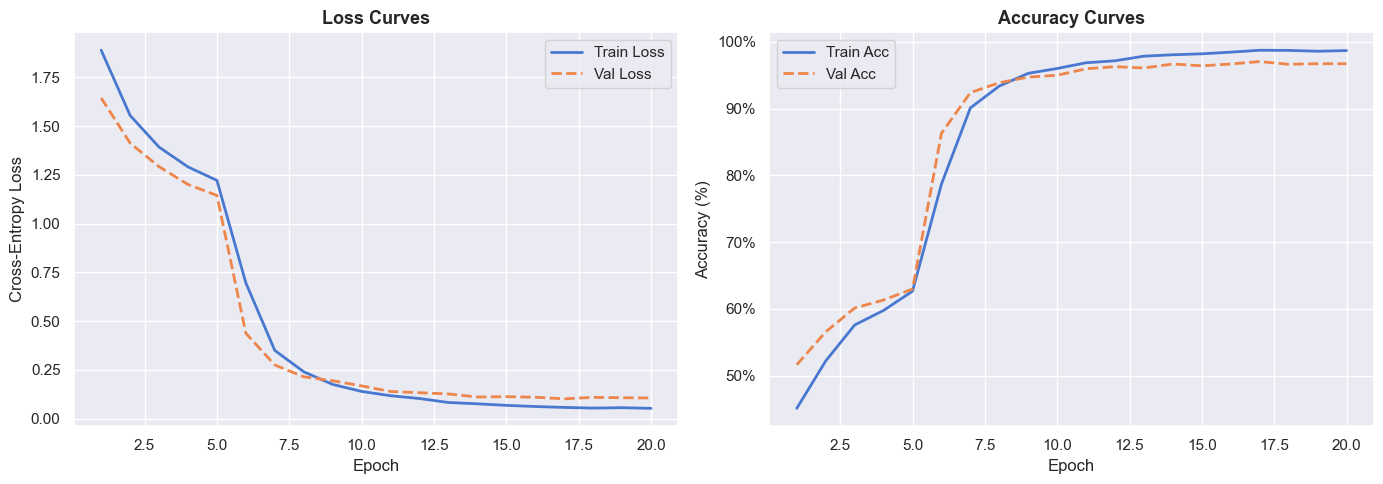

In [2]:
metrics = pd.read_csv(RUNS_DIR / 'metrics.csv')
print(metrics.head())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Loss
axes[0].plot(metrics['epoch'], metrics['train_loss'], label='Train Loss', linewidth=2)
axes[0].plot(metrics['epoch'], metrics['val_loss'],   label='Val Loss',   linewidth=2, linestyle='--')
axes[0].set_title('Loss Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].legend()

# Accuracy
axes[1].plot(metrics['epoch'], metrics['train_acc'] * 100, label='Train Acc', linewidth=2)
axes[1].plot(metrics['epoch'], metrics['val_acc']   * 100, label='Val Acc',   linewidth=2, linestyle='--')
axes[1].yaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_title('Accuracy Curves', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy (%)')
axes[1].legend()

plt.tight_layout()
plt.savefig(RUNS_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. Checkpoint Analysis

Best epoch       : 17
Best val accuracy: 97.04%
Best val loss    : 0.1011


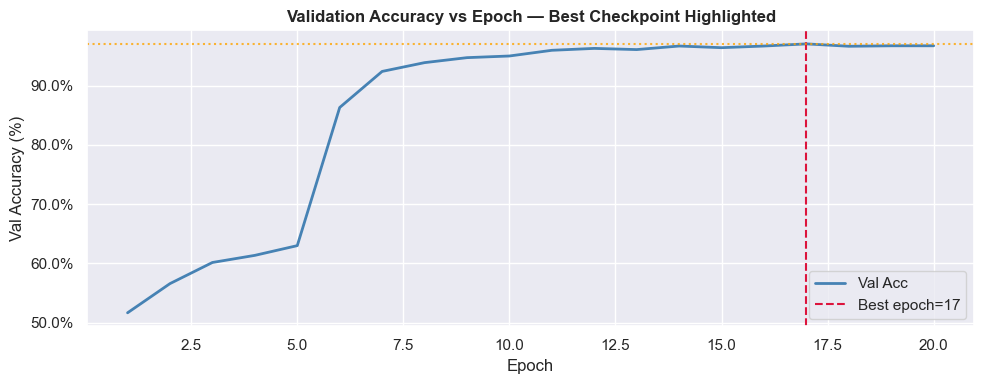

In [3]:
best_row = metrics.loc[metrics['val_acc'].idxmax()]
print(f'Best epoch       : {int(best_row["epoch"])}')
print(f'Best val accuracy: {best_row["val_acc"]*100:.2f}%')
print(f'Best val loss    : {best_row["val_loss"]:.4f}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(metrics['epoch'], metrics['val_acc'] * 100, color='steelblue', linewidth=2, label='Val Acc')
ax.axvline(best_row['epoch'], color='crimson', linestyle='--', label=f'Best epoch={int(best_row["epoch"])}')
ax.axhline(best_row['val_acc'] * 100, color='orange', linestyle=':', alpha=0.8)
ax.set_xlabel('Epoch')
ax.set_ylabel('Val Accuracy (%)')
ax.set_title('Validation Accuracy vs Epoch — Best Checkpoint Highlighted', fontweight='bold')
ax.yaxis.set_major_formatter(mticker.PercentFormatter())
ax.legend()
plt.tight_layout()
plt.savefig(RUNS_DIR / 'val_acc_checkpoint.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Baseline Performance Summary (vs Yang et al.)

In [4]:
per_class_f1 = pd.read_csv(RUNS_DIR / 'test_per_class_f1.csv')

overall_acc  = per_class_f1  # placeholder; read from results md

# Parse accuracy + macro F1 from baseline_results.md
results_md = (PROCESSED_DIR / 'baseline_results.md').read_text(encoding='utf-8')
import re
acc_match  = re.search(r'Test Accuracy.*?(\d+\.\d+)%', results_md)
f1_match   = re.search(r'Macro F1-score.*?(\d+\.\d+)', results_md)
our_acc  = float(acc_match.group(1))  if acc_match  else None
our_f1   = float(f1_match.group(1))   if f1_match   else None

summary = pd.DataFrame({
    'Model'         : ['Yang et al. - GoogleLeNet', 'Yang et al. - ResNet', 'Our ResNet18 Baseline'],
    'Accuracy (%)'  : [90.08, 88.59, our_acc],
    'Macro F1'      : ['N/A', 'N/A', f'{our_f1:.4f}' if our_f1 else 'N/A'],
    'Notes'         : ['Literature result', 'Literature result', 'Standard split, left-image only'],
})
print(summary.to_string(index=False))


                    Model  Accuracy (%) Macro F1                           Notes
Yang et al. - GoogleLeNet         90.08      N/A               Literature result
     Yang et al. - ResNet         88.59      N/A               Literature result
    Our ResNet18 Baseline         96.27   0.9351 Standard split, left-image only


## 4. Test Confusion Matrix

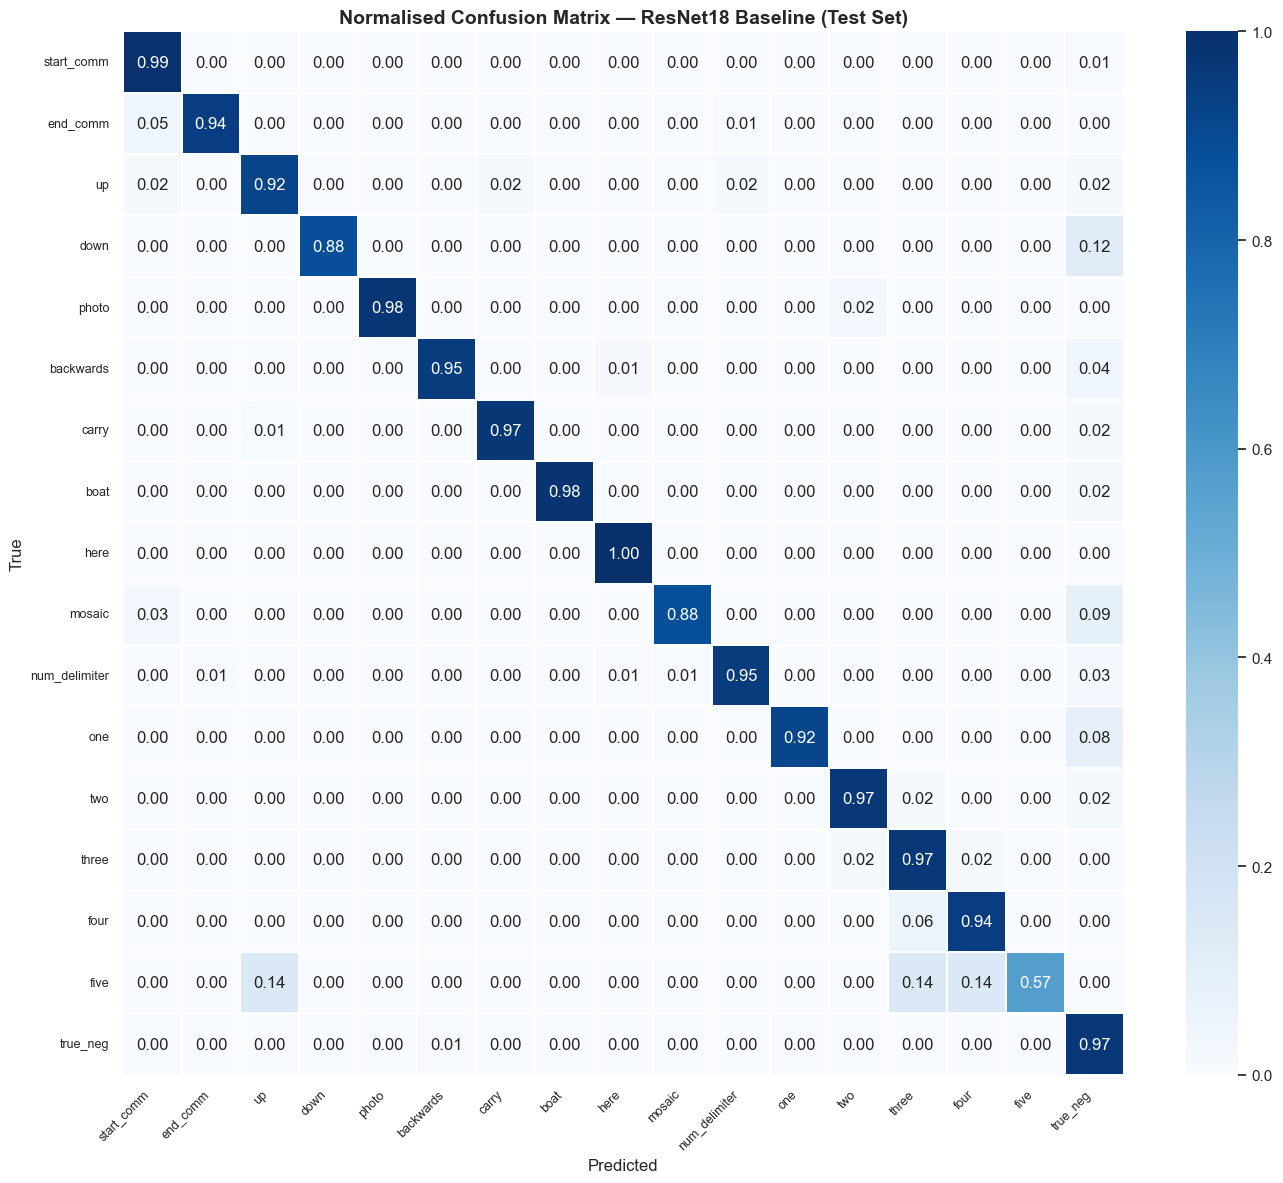

In [5]:
cm = np.load(RUNS_DIR / 'test_confusion.npy')

class_names = [
    'start_comm', 'end_comm', 'up', 'down', 'photo', 'backwards',
    'carry', 'boat', 'here', 'mosaic', 'num_delimiter', 'one',
    'two', 'three', 'four', 'five', 'true_neg',
]
class_names = class_names[:cm.shape[0]]

fig, ax = plt.subplots(figsize=(14, 12))
cm_norm = cm.astype('float') / cm.sum(axis=1, keepdims=True).clip(min=1)
sns.heatmap(
    cm_norm, annot=True, fmt='.2f', cmap='Blues',
    xticklabels=class_names, yticklabels=class_names,
    ax=ax, linewidths=0.3,
)
ax.set_title('Normalised Confusion Matrix — ResNet18 Baseline (Test Set)', fontsize=14, fontweight='bold')
ax.set_xlabel('Predicted', fontsize=12)
ax.set_ylabel('True', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(rotation=0, fontsize=9)
plt.tight_layout()
plt.savefig(RUNS_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Per-Class F1 Scores

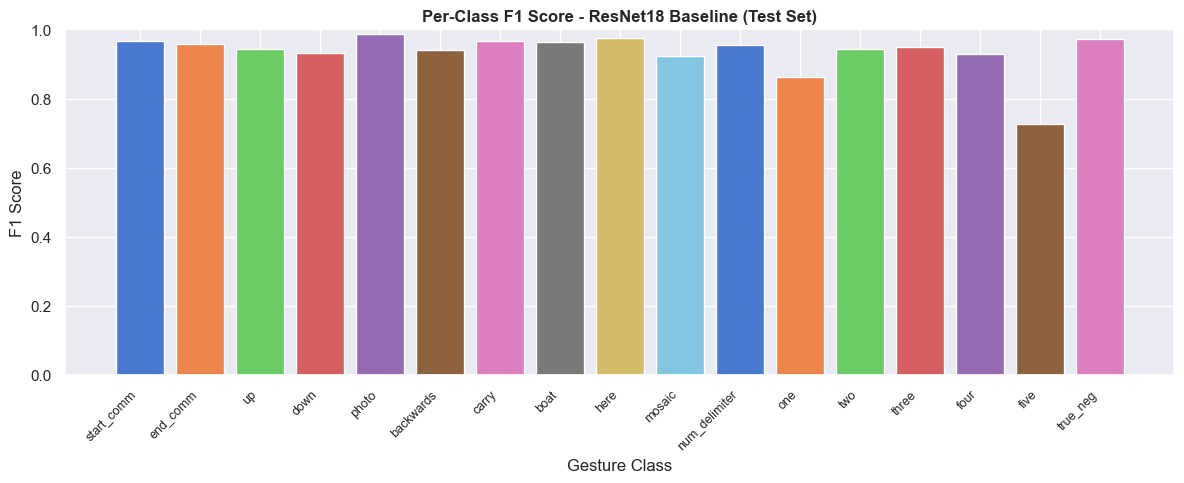

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
colors = sns.color_palette('muted', n_colors=len(per_class_f1))
bars = ax.bar(per_class_f1['class_name'], per_class_f1['f1'], color=colors)
ax.set_title('Per-Class F1 Score - ResNet18 Baseline (Test Set)', fontweight='bold')
ax.set_xlabel('Gesture Class')
ax.set_ylabel('F1 Score')
ax.set_ylim(0, 1.0)
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.savefig(RUNS_DIR / 'per_class_f1.png', dpi=150, bbox_inches='tight')
plt.show()

---
*End of Phase 4 Baseline Analysis.*

**Next step:** Proceed to Phase 5 — SENSE Model Construction,
provided the test accuracy above is non-trivial (>20%).